# Missing Value Treatment: Medical Records Dataset

## Experiment
Examine missing observations in a medical records dataset and compare three imputation strategies: **mean, median, and mode**.

The notebook preserves the code and the visible execution results from the supplied 7-page PDF. The PDF did not include the complete source CSV, so the saved outputs below are report-derived snapshots. To rerun the calculations on the original data, place `realworld_medical_dirty.csv` in this notebook's folder and run the cells from top to bottom.

### Workflow
1. Load and inspect the data.
2. Measure missing observations.
3. Visualize missingness.
4. Create separate mean, median, and mode versions.
5. Check remaining null values.
6. Compare numerical means.
7. Compare numerical standard deviations.
8. Visualize the original missing-value pattern.


## 1. Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

print("Libraries loaded.")

Libraries loaded.\n

## 2. Read and inspect the medical records file

In [2]:
# Locate the downloaded medical CSV
medical_files = glob.glob("realworld_medical_dirty*.csv")

if not medical_files:
    raise FileNotFoundError(
        "Could not find a file named realworld_medical_dirty*.csv "
        "in the notebook folder."
    )

medical_file = medical_files[0]
records = pd.read_csv(medical_file)

print("File:", medical_file)
print("Rows:", records.shape[0])
print("Columns:", records.shape[1])

# Preview the dataset
records.head()

File: realworld_medical_dirty.csv\nRows: 100\nColumns: 10\n

  Patient_ID   Age  Gender  Blood_Pressure  Cholesterol   BMI Smoker       Diagnosis Admission_Date Notes
0      P1000  55.0  FEMALE           120.0          NaN  35.4    Yes  Heart Disease     2023-12-27   NaN
1      P1001  65.0    Male           150.0        180.0  27.8    NaN            NaN     2023-01-01   NaN
2      P1002  45.0    Male           120.0        220.0  22.5     No            NaN     2023-12-14   NaN
3      P1003  65.0    Male             NaN        180.0  35.4     No            NaN     2023-07-09   NaN
4      P1004  65.0    Male           120.0        300.0  40.1    NaN            NaN     2023-07-10   Follow-up required

## 3. Count missing observations

In [3]:
# Number of null entries in every field
null_totals = records.isnull().sum()
null_totals

Patient_ID         0
Age               17
Gender            15
Blood_Pressure    14
Cholesterol       20
BMI               20
Smoker            20
Diagnosis         48
Admission_Date     0
Notes             43
dtype: int64

In [4]:
# Percentage of records missing from each field
null_rates = (records.isnull().sum() / len(records)) * 100
null_rates.sort_values(ascending=False)

Diagnosis         48.0
Notes             43.0
Smoker            20.0
Cholesterol       20.0
BMI               20.0
Age               17.0
Gender            15.0
Blood_Pressure    14.0
Patient_ID         0.0
Admission_Date     0.0
dtype: float64

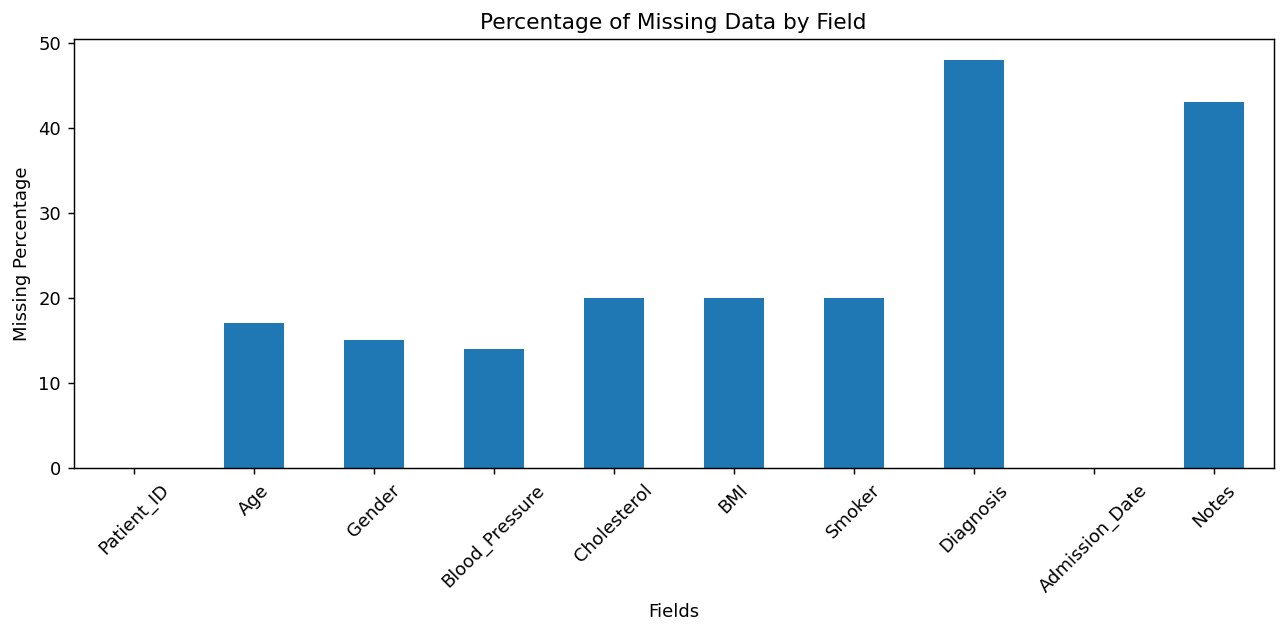

In [5]:
# Visualize the percentage of missing data
plt.figure(figsize=(10, 5))
null_rates.plot(kind="bar")
plt.title("Percentage of Missing Data by Field")
plt.ylabel("Missing Percentage")
plt.xlabel("Fields")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Prepare three imputation copies

A separate copy is retained for each method so that the original measurements remain unchanged.

For numerical fields:
- Mean replacement uses the arithmetic average.
- Median replacement uses the middle value.

For non-numerical fields, the mode is used because arithmetic mean and median are not meaningful.

In [6]:
# Separate numeric and non-numeric variables
numeric_fields = records.select_dtypes(include="number").columns
text_fields = records.select_dtypes(include="object").columns
print("Numerical fields:")
print(list(numeric_fields))
print("\\nNon-numerical fields:")
print(list(text_fields))

# Make independent datasets for the three approaches
mean_version = records.copy()
median_version = records.copy()
mode_version = records.copy()

Numerical fields:
['Age', 'Blood_Pressure', 'Cholesterol', 'BMI']

Non-numerical fields:
['Patient_ID', 'Gender', 'Smoker', 'Diagnosis', 'Admission_Date', 'Notes']


## 5. Mean-based replacement

In [7]:
# Mean for numeric data; mode for categorical/text data
for field in numeric_fields:
    mean_version[field] = mean_version[field].fillna(mean_version[field].mean())

for field in text_fields:
    mean_version[field] = mean_version[field].fillna(mean_version[field].mode()[0])

mean_version.isnull().sum()

Patient_ID        0
Age               0
Gender            0
Blood_Pressure    0
Cholesterol       0
BMI               0
Smoker            0
Diagnosis         0
Admission_Date    0
Notes             0
dtype: int64

## 6. Median-based replacement

In [8]:
# Median for numeric data; mode for categorical/text data
for field in numeric_fields:
    median_version[field] = median_version[field].fillna(median_version[field].median())

for field in text_fields:
    median_version[field] = median_version[field].fillna(median_version[field].mode()[0])

median_version.isnull().sum()

Patient_ID        0
Age               0
Gender            0
Blood_Pressure    0
Cholesterol       0
BMI               0
Smoker            0
Diagnosis         0
Admission_Date    0
Notes             0
dtype: int64

## 7. Mode-based replacement

In [9]:
# Replace null entries everywhere with the modal value
for field in mode_version.columns:
    mode_version[field] = mode_version[field].fillna(mode_version[field].mode()[0])

mode_version.isnull().sum()

Patient_ID        0
Age               0
Gender            0
Blood_Pressure    0
Cholesterol       0
BMI               0
Smoker            0
Diagnosis         0
Admission_Date    0
Notes             0
dtype: int64

## 8. Compare the remaining missing entries

In [10]:
# Total number of missing cells under each approach
remaining_nulls = {
    "Before treatment": int(records.isnull().sum().sum()),
    "Mean method": int(mean_version.isnull().sum().sum()),
    "Median method": int(median_version.isnull().sum().sum()),
    "Mode method": int(mode_version.isnull().sum().sum())
}
remaining_nulls

{'Before treatment': 197,
 'Mean method': 0,
 'Median method': 0,
 'Mode method': 0}

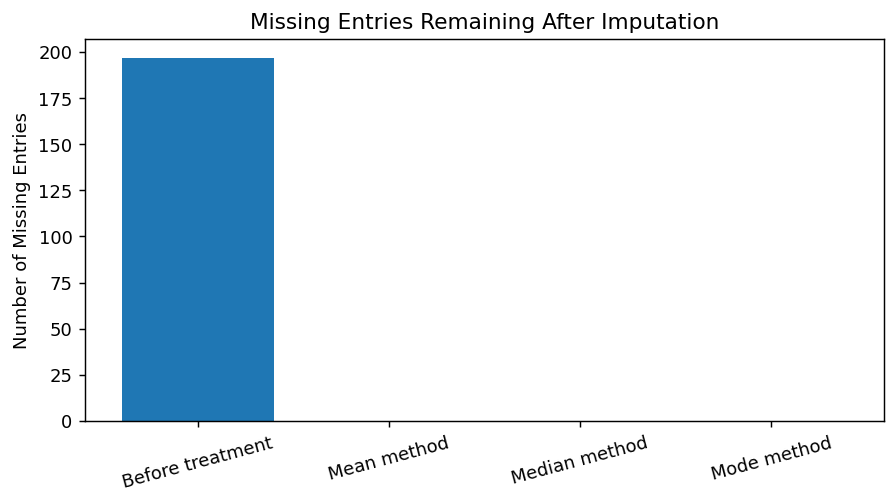

In [11]:
# Plot the totals
plt.figure(figsize=(7, 4))
plt.bar(remaining_nulls.keys(), remaining_nulls.values())
plt.title("Missing Entries Remaining After Imputation")
plt.ylabel("Number of Missing Entries")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 9. Compare numerical means

In [12]:
# Mean values before and after each treatment
mean_table = pd.DataFrame({
    "Original": records[numeric_fields].mean(),
    "Mean method": mean_version[numeric_fields].mean(),
    "Median method": median_version[numeric_fields].mean(),
    "Mode method": mode_version[numeric_fields].mean()
})
mean_table

                 Original  Mean method  Median method  Mode method
Age              47.168675    47.168675         48.500       48.500
Blood_Pressure  137.093023   137.093023        137.500      134.700
Cholesterol     226.750000   226.750000        225.400      217.400
BMI              32.228750    32.228750         32.863       32.863

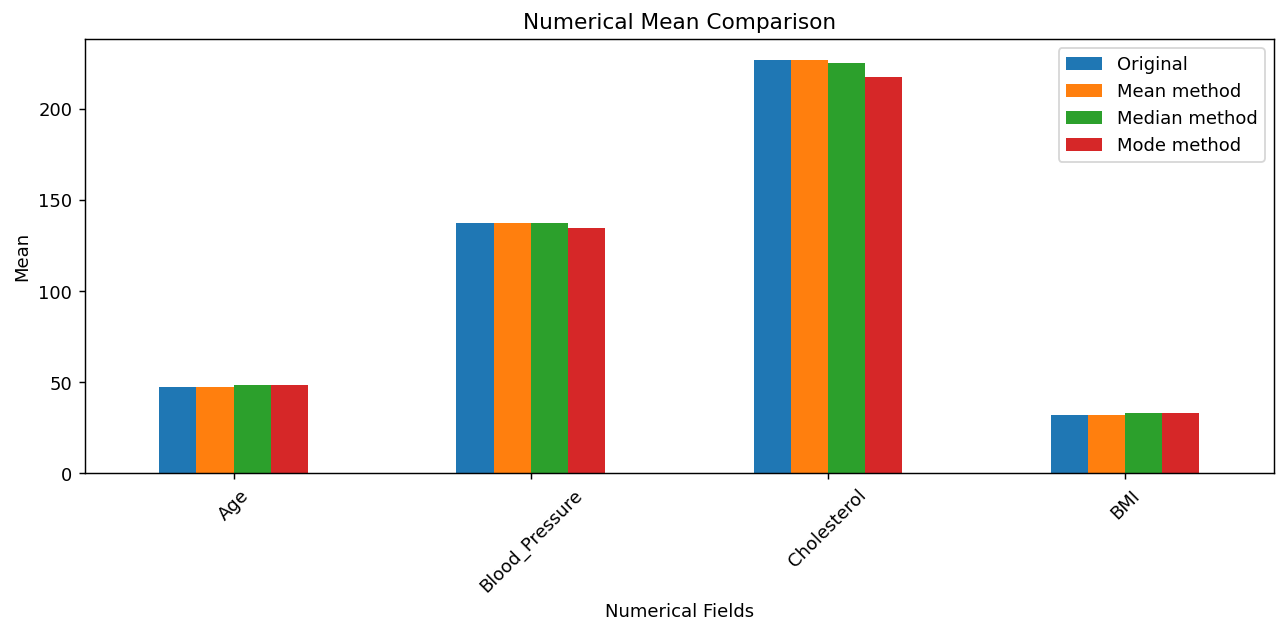

In [13]:
# Graph the mean comparison
mean_table.plot(kind="bar", figsize=(10, 5))
plt.title("Numerical Mean Comparison")
plt.ylabel("Mean")
plt.xlabel("Numerical Fields")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 10. Compare standard deviations

In [14]:
# Standard deviations for the original and completed datasets
spread_table = pd.DataFrame({
    "Original": records[numeric_fields].std(),
    "Mean method": mean_version[numeric_fields].std(),
    "Median method": median_version[numeric_fields].std(),
    "Mode method": mode_version[numeric_fields].std()
})
spread_table

                 Original  Mean method  Median method  Mode method
Age              13.619229    12.394866      12.742595    12.742595
Blood_Pressure   13.360722    12.380033      12.421470    13.740378
Cholesterol      43.217876    38.606405      38.701656    42.938057
BMI               6.237437     5.571885       5.715876     5.715876

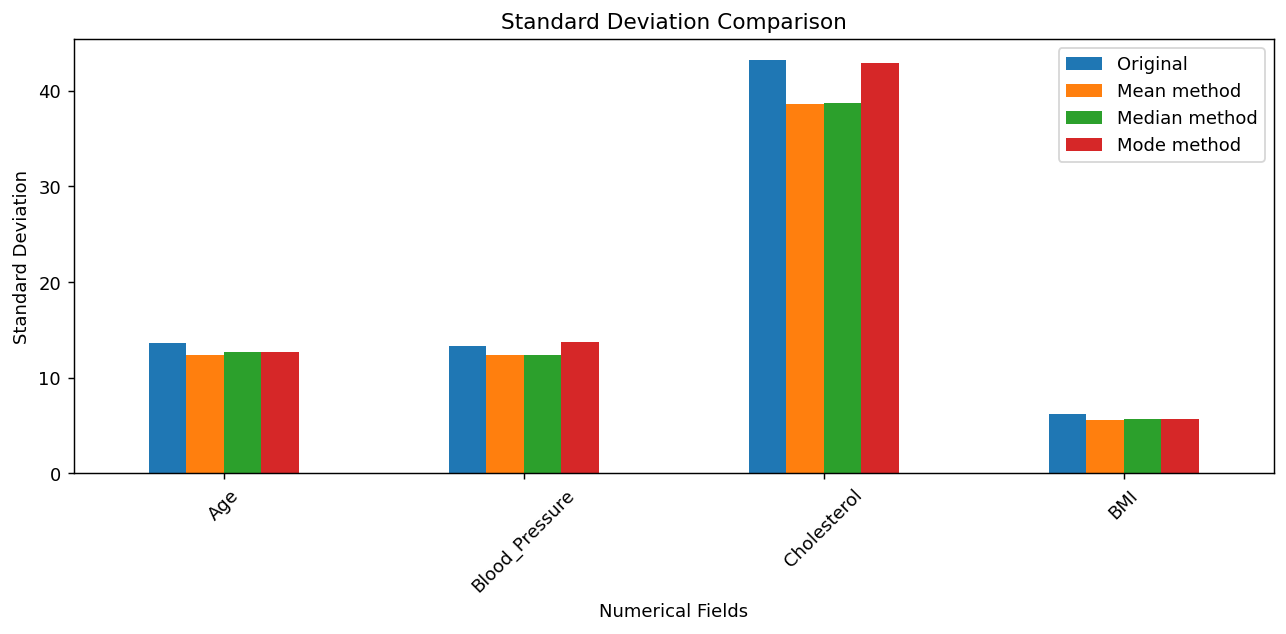

In [15]:
# Graph the standard-deviation comparison
spread_table.plot(kind="bar", figsize=(10, 5))
plt.title("Standard Deviation Comparison")
plt.ylabel("Standard Deviation")
plt.xlabel("Numerical Fields")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 11. Missing-value heatmap

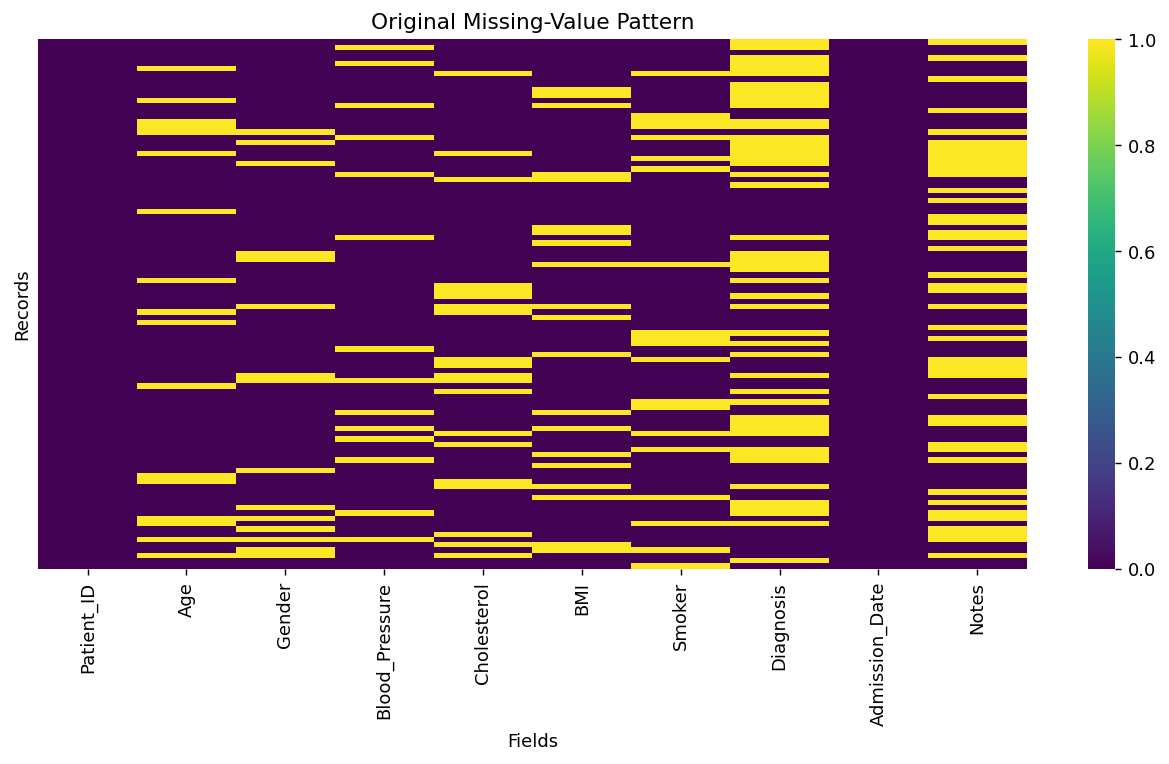

In [16]:
# Display the original missing-data pattern
plt.figure(figsize=(10, 6))
sns.heatmap(
    records.isnull(),
    cbar=True,
    cmap="viridis",
    yticklabels=False
)
plt.title("Original Missing-Value Pattern")
plt.xlabel("Fields")
plt.ylabel("Records")
plt.tight_layout()
plt.show()

## Conclusion

The report shows **197 missing cells** before treatment. Mean, median, and mode imputation each reduce the remaining missing-cell count to **zero**. The mean and standard-deviation comparisons show that the imputation strategy affects the numerical distributions differently.

### Important note about the saved outputs
The original CSV was not embedded in the PDF. Therefore, the displayed output snapshots and comparison charts above are reconstructed from the values visible in the PDF. The missingness heatmap is a representative reconstruction of the pattern, not the original pixel-for-pixel plot. Once the original CSV is placed beside the notebook, running all cells will regenerate the actual outputs from the dataset.
